In [ ]:
from random import getrandbits, randint, random, choice

In [ ]:
def individual(n_de_itens):
    """Cria um membro da populacao"""
    return [ getrandbits(1) for x in range(n_de_itens) ]

In [ ]:
def population(n_de_individuos, n_de_itens):
    """"Cria a populacao"""
    return [ individual(n_de_itens) for x in range(n_de_individuos) ]

In [ ]:
def fitness(individuo, peso_maximo, pesos_e_valores):
    """Faz avaliacao do individuo"""
    peso_total, valor_total = 0, 0
    for indice, valor in enumerate(individuo):
        peso_total += (individuo[indice] * pesos_e_valores[indice][0])
        valor_total += (individuo[indice] * pesos_e_valores[indice][1])

    if (peso_maximo - peso_total) < 0:
        return -1 #retorna -1 no caso de peso excedido
    return valor_total #se for um individuo valido retorna seu valor, sendo maior melhor

In [ ]:
def media_fitness(populacao, peso_maximo, pesos_e_valores): #só leva em consideracao os elementos que respeitem o peso maximo da mochila
    """Encontra a avalicao media da populacao"""
    summed = sum(fitness(x, peso_maximo, pesos_e_valores) for x in populacao if fitness(x, peso_maximo, pesos_e_valores) >= 0)
    return summed / (len(populacao) * 1.0)

In [ ]:
def sortear(valores,fitness_total, indice_a_ignorar=-1): #2 parametro garante que não vai selecionar o mesmo elemento
        """Monta roleta para realizar o sorteio"""
        roleta, acumulado, valor_sorteado = [], 0, random()

        if indice_a_ignorar!=-1: #Desconta do total, o valor que sera retirado da roleta
            fitness_total -= valores[0][indice_a_ignorar]

        for indice, i in enumerate(valores[0]):
            if indice_a_ignorar==indice: #ignora o valor ja utilizado na roleta
                continue
            acumulado += i
            roleta.append(acumulado/fitness_total)
            if roleta[-1] >= valor_sorteado:
                return indice

In [ ]:
def selecao_roleta(pais):
    """Seleciona um pai e uma mae baseado nas regras da roleta"""

    valores = list(zip(*pais)) #cria 2 listas com os valores fitness e os cromossomos
    fitness_total = sum(valores[0])

    indice_pai = sortear(valores,fitness_total)
    indice_mae = sortear(valores,fitness_total, indice_pai)

    pai = valores[1][indice_pai]
    mae = valores[1][indice_mae]

    return pai, mae

In [ ]:
def evolve(populacao, peso_maximo, pesos_e_valores, n_de_cromossomos, mutate=0.05):
    """Tabula cada individuo e o seu fitness"""
    pais = [ [fitness(x, peso_maximo, pesos_e_valores), x] for x in populacao if fitness(x, peso_maximo, pesos_e_valores) >= 0]
    pais.sort(reverse=True)

    # REPRODUCAO
    filhos = []
    while len(filhos) < n_de_cromossomos:
        homem, mulher = selecao_roleta(pais)
        meio = len(homem) // 2
        filho = homem[:meio] + mulher[meio:]
        filhos.append(filho)

    # MUTACAO
    for individuo in filhos:
        if mutate > random():
            pos_to_mutate = randint(0, len(individuo)-1)
            if individuo[pos_to_mutate] == 1:
                individuo[pos_to_mutate] = 0
            else:
                individuo[pos_to_mutate] = 1

    return filhos

In [ ]:
#[peso,valor]
pesos_e_valores = [[4, 30], [8, 10], [8, 30], [25, 75], \
                  [2, 10], [50, 100], [6, 300], [12, 50], \
                  [100, 400], [8, 300],[7,20],[6,45],[13,89]]

peso_maximo = 100
n_de_cromossomos = 400
geracoes = 150
n_de_itens = len(pesos_e_valores) #Analogo aos pesos e valores

In [ ]:
# Base de dados das ações: [Risco (%), Retorno (%)]
pesos_e_valores = [
    [2.48, 0.37],  # BBAS3 - Banco Brasil ON
    [2.16, 0.24],  # BBDC4 - Bradesco PN
    [1.95, 0.14],  # ELET6 - Eletrobrás PNB
    [2.93, 0.30],  # GGBR4 - Gerdau PN
    [2.40, 0.24],  # ITSA4 - Itausa PN
    [2.00, 0.19],  # PETR4 - Petrobras PN
    [2.63, 0.28],  # CSNA3 - Sid Nacional ON
    [2.14, 0.18],  # TNLP4 - Telemar PN
    [2.73, 0.25],  # USIM5 - Usiminas PNA
    [2.47, 0.24],  # VALE5 - Vale PNA
    [2.70, 0.31],  # MGLU3 - Magalu
    [2.13, 0.26],  # HAPV3 - Hapvida
    [2.00, 0.33],  # BRAV2 - Boa Vista S.A
    [2.20, 0.23],  # ESPA3 - Espacolaser
    [1.99, 0.29],  # POWE3 - Focus Energia
    [2.83, 0.32],  # HBRE3 - HBR Realty
    [2.65, 0.22],  # CMIN3 - CSN Mineração
    [2.80, 0.30],  # INTB3 - Intelbras
    [2.32, 0.23],  # CASH3 - Méliuz S.A.
    [2.16, 0.25],  # MOSI3 - Mosaico
    [2.65, 0.25],  # SEQL3 - Simpar S.A.
    [2.50, 0.25],  # VAMO3 - Vamos
    [2.53, 0.27]   # WEST3 - Westwing
]



peso_maximo = 30
n_de_cromossomos = 100
geracoes = 150
n_de_itens = len(pesos_e_valores) #Analogo aos pesos e valores

In [ ]:
#[peso,valor]
pesos_e_valores = [[4, 30], [8, 10], [8, 30], [25, 75], \
                  [2, 10], [50, 100], [6, 300], [12, 50], \
                  [100, 400], [8, 300],[7,20],[6,45],[13,89],\
                   [20,60],[10,65],[30,150],[40,250],[56,160]]

peso_maximo = 100
n_de_cromossomos = 50
geracoes = 150
n_de_itens = len(pesos_e_valores) #Analogo aos pesos e valores

In [ ]:
#[peso,valor]
pesos_e_valores = [[4, 30], [8, 10], [8, 30], [25, 75], \
                  [2, 10], [50, 100], [6, 300], [12, 50], \
                  [100, 400], [8, 300],[7,20],[6,45],[13,89],\
                   [20,60],[10,65],[30,150],[40,250],[56,160]]

peso_maximo = 100
n_de_cromossomos = 50
geracoes = 150
n_de_itens = len(pesos_e_valores) #Analogo aos pesos e valores

In [ ]:
#[peso,valor]
pesos_e_valores = [[4, 30], [8, 10], [8, 30], [25, 75], \
                  [2, 10], [50, 100], [6, 300], [12, 50], \
                  [100, 400], [8, 300],[7,20],[6,45],[13,89],\
                   [20,60],[10,65],[30,150],[40,250],[56,160]]

peso_maximo = 100
n_de_cromossomos = 50
geracoes = 150
n_de_itens = len(pesos_e_valores) #Analogo aos pesos e valores

In [ ]:
#EXECUCAO DOS PROCEDIMENTOS
populacao = population(n_de_cromossomos, n_de_itens)
historico_de_fitness = [media_fitness(populacao, peso_maximo, pesos_e_valores)]
for i in range(geracoes):
    populacao = evolve(populacao, peso_maximo, pesos_e_valores, n_de_cromossomos)
    historico_de_fitness.append(media_fitness(populacao, peso_maximo, pesos_e_valores))


In [ ]:
#PRINTS DO TERMINAL
for indice,dados in enumerate(historico_de_fitness):
   print ("Geracao: ", indice," | Media de valor na mochila: ", dados)

print("\nPeso máximo:",peso_maximo,"g\n\nItens disponíveis:")
for indice,i in enumerate(pesos_e_valores):
    print("Item ",indice+1,": ",i[0],"g | R$",i[1])

print("\nExemplos de boas solucoes: ")
for i in range(5):
    print(populacao[i])

populacaoVisual = [fitness(populacao[0], peso_maximo, pesos_e_valores),populacao[0]]

print("\nExemplos de boas solucoes: ")
for i in range(n_de_cromossomos):
    populacaoVisual.append([fitness(populacao[i], peso_maximo, pesos_e_valores),populacao[i]])

#populacaoVisual.sort(key=takeSecond,reverse=True)
populacaoVisual

Geracao:  0  | Media de valor na mochila:  1.6666999999999998
Geracao:  1  | Media de valor na mochila:  2.1636
Geracao:  2  | Media de valor na mochila:  2.3819999999999997
Geracao:  3  | Media de valor na mochila:  2.4083
Geracao:  4  | Media de valor na mochila:  2.4664
Geracao:  5  | Media de valor na mochila:  2.5499
Geracao:  6  | Media de valor na mochila:  2.5748
Geracao:  7  | Media de valor na mochila:  2.5443000000000002
Geracao:  8  | Media de valor na mochila:  2.5898000000000003
Geracao:  9  | Media de valor na mochila:  2.6054000000000004
Geracao:  10  | Media de valor na mochila:  2.6087000000000002
Geracao:  11  | Media de valor na mochila:  2.6379
Geracao:  12  | Media de valor na mochila:  2.6538
Geracao:  13  | Media de valor na mochila:  2.7085000000000004
Geracao:  14  | Media de valor na mochila:  2.705
Geracao:  15  | Media de valor na mochila:  2.7248
Geracao:  16  | Media de valor na mochila:  2.7653000000000003
Geracao:  17  | Media de valor na mochila:  2.77

[2.99,
 [1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1],
 [2.99, [1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1]],
 [3.3200000000000003,
  [1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1]],
 [3.0700000000000003,
  [1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1]],
 [3.3200000000000003,
  [1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1]],
 [3.03, [1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1]],
 [3.0100000000000002,
  [1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1]],
 [3.0700000000000003,
  [1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1]],
 [3.3200000000000003,
  [1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1]],
 [2.66, [0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0]],
 [3.3200000000000003,
  [1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1]],
 [2.9, [0

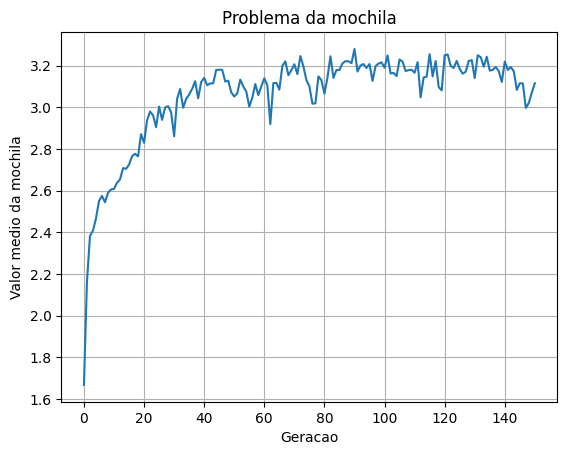

In [ ]:
#GERADOR DE GRAFICO
from matplotlib import pyplot as plt
plt.plot(range(len(historico_de_fitness)), historico_de_fitness)
plt.grid(True, zorder=0)
plt.title("Problema da mochila")
plt.xlabel("Geracao")
plt.ylabel("Valor medio da mochila")
plt.show()